# 02 · Forwards, implied volatilities, Greeks, and verification

**In the story** (notebook 00, §§2–3 and §6): every hedge ratio in the study is built from the quantities made here: each expiry's forward and discount factor, each option's implied volatility, and its Black–Scholes delta, vega and vanna. This notebook also sets up sensitivity A, which checks the synchronous-quotes assumption after finding that the option quotes are synchronous with neither index series. It also runs the test suite.

Lecture 9 prices with a continuous dividend yield q. The S&P 500's dividends come from 500 companies on scattered dates, so no single q is observable. Instead, every expiry is priced on its own *forward* F and discount factor D, both read from put–call parity at the mids (Lectures 6 and 9):

  C − P = D·(F − K).

The three stages (`analysis_plan.md` §4) are:
1. A weighted least-squares line of C − P on K, per expiry, on strikes within 10% of the index where both legs are quoted.
2. A smooth zero-rate curve r(τ) per session, from the expiries at least 30 days out, because a short expiry pins down D poorly.
3. Each expiry's forward, given D.

The price is Black's formula C = D·[F·N(d₁) − K·N(d₂)]. It equals Lecture 9's formula with r = −ln(D)/τ and q = r − ln(F/S)/τ. Implied volatilities come from Lecture 12's solver, `option_pricing.bs_euro_iv`.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R = ROOT / "results"
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": 0.3})

Text(0.5, 1.0, "The options' own discount rate, 2019–2020")

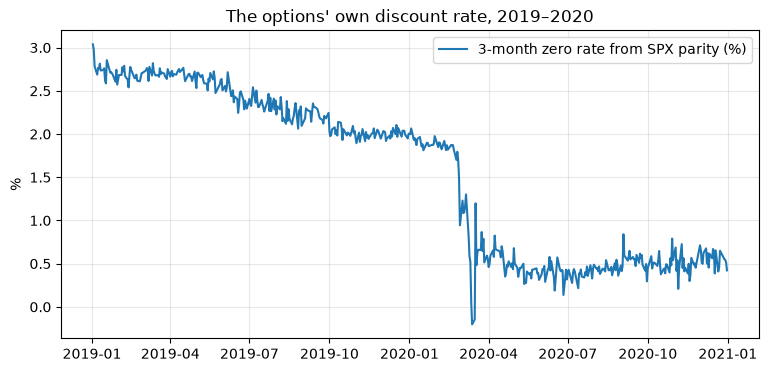

In [2]:
s = pd.read_csv(R / "attrition/parity_sessions.csv", parse_dates=["quote_date"])
fig, ax = plt.subplots()
ax.plot(s.quote_date, 100 * (s.c0 + s.c1 * 0.25), label="3-month zero rate from SPX parity (%)")
ax.set_ylabel("%"); ax.legend(); ax.set_title("The options' own discount rate, 2019–2020")

**Reading.** The parity rate follows the policy cuts of 2019 and the March 2020 emergency cuts to near zero. It sits a little above Treasury bill yields, which is typical of rates implied by SPX options: they are a funding rate, not a government rate.

In [3]:
s[["n_fits", "stage1_fits", "stage3_forwards", "expiries", "A_days"]].describe().round(2)

,n_fits,stage1_fits,stage3_forwards,expiries,A_days
count,497.00,497.00,497.00,497.00,495.00
mean,23.02,35.73,35.74,36.44,2.32
std,2.21,2.23,2.23,2.25,1.37
min,18.00,31.00,31.00,32.00,0.88
25%,22.00,34.00,34.00,35.00,1.00
50%,23.00,35.00,35.00,36.00,2.00
75%,24.00,37.00,37.00,38.00,3.00
max,28.00,40.00,40.00,41.00,9.00


## Implied-volatility solver statuses

Only a converged solve gives an implied volatility. Mids outside the no-arbitrage bounds are nearly all deep-in-the-money quotes, outside the delta band.

In [4]:
pd.read_csv(R / "attrition/iv_status.csv", index_col=0)

,2019,2020
iv_status,,
converged,2465688,3061617
outside_price_bounds,190157,175191
one_sided,180757,160859
expired,56818,75620
no_forward,11046,6
above_volatility_bracket,58,261


## A parity-consistency check

If the mids satisfy parity at the fitted D and F, a single σ prices both the call and the put at a strike. The gap between their implied volatilities, by log-moneyness ln(K/F), measures how well that holds.

In [5]:
pd.read_csv(R / "attrition/cp_iv_gap.csv").round(4)

,m,count,mean,std,min,25%,50%,75%,max
0,"(-0.1, -0.075]",64614.0,-0.0001,0.0062,-0.1665,-0.0013,0.0,0.0013,0.1445
1,"(-0.075, -0.05]",69835.0,-0.0000,0.0050,-0.1336,-0.0011,-0.0,0.0011,0.1196
2,"(-0.05, -0.025]",73819.0,-0.0000,0.0042,-0.1141,-0.0009,-0.0,0.0009,0.2400
3,"(-0.025, 0.0]",75946.0,0.0000,0.0045,-0.6676,-0.0007,-0.0,0.0007,0.1784
4,"(0.0, 0.025]",75833.0,0.0000,0.0039,-0.1112,-0.0008,0.0,0.0008,0.3153
5,"(0.025, 0.05]",69432.0,-0.0001,0.0054,-0.1271,-0.0011,0.0,0.0011,0.2326
6,"(0.05, 0.075]",55746.0,-0.0002,0.0085,-0.1354,-0.0016,-0.0,0.0014,0.1438
7,"(0.075, 0.1]",42604.0,-0.0004,0.0125,-0.1248,-0.0024,-0.0,0.0018,0.1845


## Sensitivity A's index level

The audit found the option quotes are synchronous with neither the official close nor the vendor's snapshot. Sensitivity A therefore uses the level implied by the options themselves: the parity forward of the nearest P.M. expiry with a successful fit 0.5–5 days out, falling back to the nearest successful fit up to 10 days out.

count    495.00
mean       4.63
std        5.08
min        0.01
25%        1.65
50%        3.27
75%        5.66
max       49.12
Name: gap_bp, dtype: float64

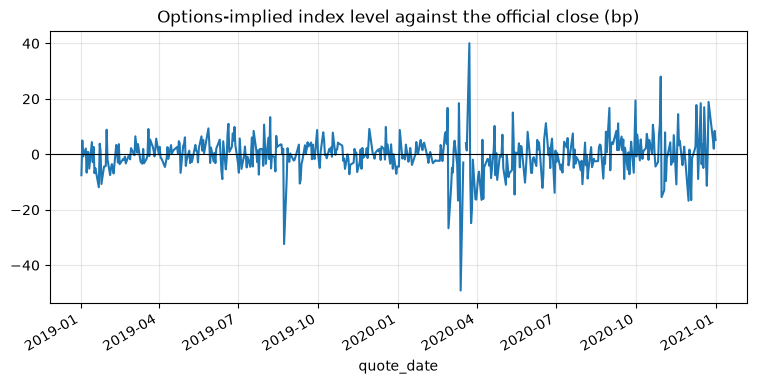

In [6]:
s["gap_bp"] = 1e4 * np.log(s.S_A / s.S_close)
ax = s.set_index("quote_date").gap_bp.plot(title="Options-implied index level against the official close (bp)")
ax.axhline(0, color="k", lw=0.8)
s.gap_bp.abs().describe().round(2)

## Verification (`analysis_plan.md` §11)

The pytest suite checks:
- the forward-form Greeks against central finite differences;
- agreement with Lecture 12's `bs_euro_greeks` and `bs_euro_iv`;
- implied-volatility round trips and bound failures;
- recovery of a known D and F by the parity fit;
- recovery of known Hull–White coefficients;
- Gain invariance;
- the no-look-ahead boundary;
- the bootstrap identity;
- the learners' objective;
- the mark formulas.

In [7]:
import subprocess
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", str(ROOT / "tests")], capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-1500:])

............................................                             [100%]
44 passed in 8.45s

